# Question 2

In [4]:
import subprocess

subprocess.run(["cyclus", "./breed_and_burn.xml"])


              :                                                               
          .CL:CC CC             _Q     _Q  _Q_Q    _Q    _Q              _Q   
        CC;CCCCCCCC:C;         /_\)   /_\)/_/\\)  /_\)  /_\)            /_\)  
        CCCCCCCCCCCCCl       __O|/O___O|/O_OO|/O__O|/O__O|/O____________O|/O__
     CCCCCCf     iCCCLCC     /////////////////////////////////////////////////
     iCCCt  ;;;;;.  CCCC                                                      
    CCCC  ;;;;;;;;;. CClL.                          c                         
   CCCC ,;;       ;;: CCCC  ;                   : CCCCi                       
    CCC ;;         ;;  CC   ;;:                CCC`   `C;                     
  lCCC ;;              CCCC  ;;;:             :CC .;;. C;   ;    :   ;  :;;   
  CCCC ;.              CCCC    ;;;,           CC ;    ; Ci  ;    :   ;  :  ;  
   iCC :;               CC       ;;;,        ;C ;       CC  ;    :   ; .      
  CCCi ;;               CCC        ;;;.      .C ;   

Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental



Status: Cyclus run successful!
Output location: cyclus.sqlite
Simulation ID: 1b49b95b-fff3-4c03-bc81-0ecc3fe7327a


CompletedProcess(args=['cyclus', './breed_and_burn.xml'], returncode=0)

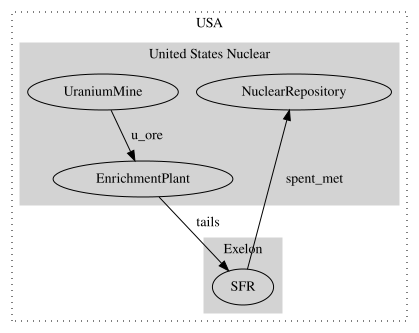

In [5]:
import cymetric as cym 
from cymetric import graphs as cgr
from cymetric import timeseries

import matplotlib.pyplot as plt

cdb = cym.dbopen("cyclus.sqlite")
ev = cym.Evaluator(db=cdb,write=False)
cgr.flow_graph(ev, label='comm')

**Part a)** 

Total Natural Uranium Supplied in the Breed and Burn Fuel Cycle: 1136.45 MTU


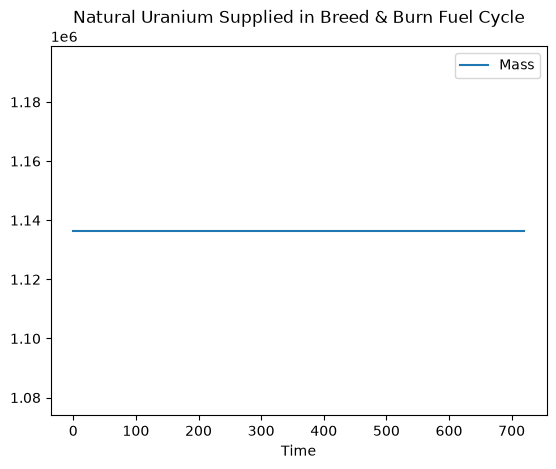

In [34]:
import numpy as np
time = np.arange(0,721)

u=cym.filters.transactions_nuc(ev,commodities=["u_ore"])

u = u.groupby("Time")[["Mass"]].sum()
# u.to_csv("mined_u.csv")
u=u.cumsum()

print(f"Total Natural Uranium Supplied in the Breed and Burn Fuel Cycle: {round(u.iloc[-1, u.columns.get_loc('Mass')]/1000,2)} MTU")

# Only one 'Mass' value was generated, so it's a bit annoying make a plot for a single value
u_mass = np.full(721,u.Mass[1])
plt.plot(time, u_mass,label='Mass')
plt.title('Natural Uranium Supplied in Breed & Burn Fuel Cycle')
plt.xlabel('Time')
plt.legend()

**Part b)**

In [35]:
# Only initial loading needs mined uranium, rest is from leftover tails...
tot_batches = 15

# M_nat = M_fuel*(0.080 - 0.003)/(0.00711 - 0.003)
# where M_fuel = tot_batches * (4044 kgU/batch)
m_nat = tot_batches*(4044)*((8.00 - 0.3)/(0.711 - 0.3))

print(f"Cyclus Total Natural Uranium Supplied: {round(u.iloc[-1, u.columns.get_loc('Mass')]/1000,2)} MTU")
print(f"Hand Calc Total Natural Uranium Supplied: {round(m_nat/1000,2)} MTU")


Cyclus Total Natural Uranium Supplied: 1136.45 MTU
Hand Calc Total Natural Uranium Supplied: 1136.45 MTU


**Part c)**

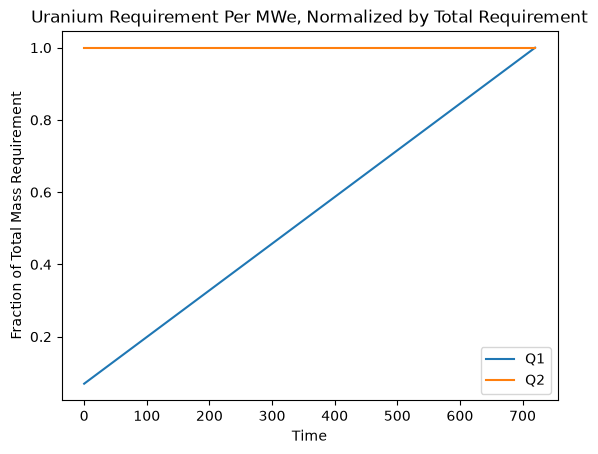

In [ ]:
# To be quite frank, I do not understand what this question wants me to quantify
# Otherwise, Q1's required natural uranium increases linearly according to time,
#       particularly becuase fresh UOx is needed for each reload
# Q2's required required natural uranium only has one data point at the beginning
#       of the 'simulation,' so its requirement remains the same over time;
#       each reload only needs tails so uranium is only ever mined at the first time step
cumulative_time = np.cumsum(time)
u2_req_power = (u_mass/1000)/480
u2_req_power_norm = u2_req_power/u2_req_power[-1]

db1 = cym.dbopen("/workspaces/Workshop-Codespace/ne550/q1/cyclus.sqlite")
ev1 = cym.Evaluator(db=db1,write=False)
u1 = cym.filters.transactions_nuc(ev1,commodities=["u_ore"])
u1 = u1.groupby("Time")[["Mass"]].sum()
u1 = u1.cumsum()
u1_mass = u1["Mass"].to_numpy()

u1_req_power = (u1_mass/1000)/1148
u1_req_power_norm = u1_req_power/u1_req_power[-1]
time1 = np.linspace(0,720,len(u1_req_power))

plt.plot(time1, u1_req_power_norm,label='Q1')
plt.plot(time,u2_req_power_norm,label='Q2')
plt.xlabel('Time')
plt.ylabel('Fraction of Total Mass Requirement')
plt.title('Uranium Requirement Per MWe, Normalized by Total Requirement')
plt.legend()


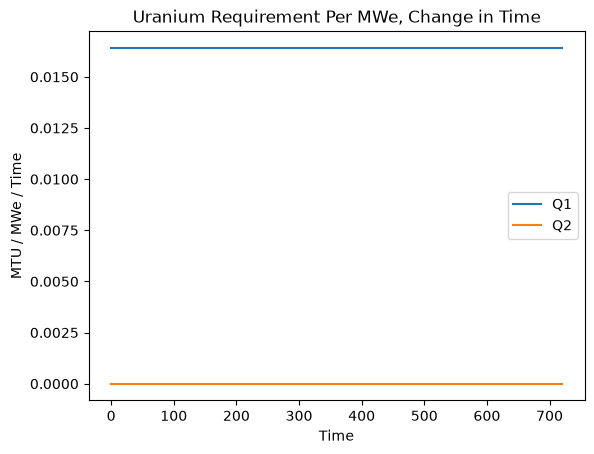

In [68]:
u1_deriv = np.gradient(u1_req_power, time1)
u2_deriv = np.gradient(u2_req_power, time)

plt.plot(time1, u1_deriv,label='Q1')
plt.plot(time,u2_deriv,label='Q2')
plt.xlabel('Time')
plt.ylabel("MTU / MWe / Time")
plt.title('Uranium Requirement Per MWe, Change in Time')
plt.legend()

**Part d)**

In [75]:
# BU = (480 MWe)*(1/0.33 MWth/MWe) * (15 cycles)*(47 months/cycle)*(31 days/month) / (60.66 MTU)
bu = 480*(1/0.33)*(15*47*31)/60.66

# This number is only applicable to the tail-made assemblies that remain there for 15 cycles at a time
# Might be reasonable since SFRs can get into hundreds of GWD/MTU for burnups, but accounting for 
#       actual assembly powers and loadings will likely bring the value down to a more
#       realistic estimate
print(f"Batch-wise Average Discharge Burnup: {round(bu,2)} MWD/MTU")

Batch-wise Average Discharge Burnup: 524053.59 MWD/MTU


**Part e)**

In [72]:
# Nat. U Utilization = (M_nat,tot) / ((480 MWe) * (Years of Operation))
# Years of Operation = (720 months)/(12 months/yr) - Total Reload Time
# Total Reload Years = ((1 reload/cycle)* (720 months)/(48 months/cycle)) / (12 months/yr)
nat_u_util = m_nat / (480*((720/12)-((720/48)/12)))

print(f"Natural Uranium Utilization per EFPY: {round(nat_u_util,2)} MTU/EFPY")

Natural Uranium Utilization per EFPY: 40.3 MTU/EFPY


**Part f)**

In [ ]:
# Only initial loading needs mined uranium, rest is from leftover tails...
tot_batches = 10

# M_nat = M_fuel*(0.080 - 0.003)/(0.00711 - 0.003)
# where M_fuel = tot_batches * (4044 kgU/batch)
m_nat2 = tot_batches*(4044)*((8.00 - 0.3)/(0.711 - 0.3))

# Similar to previous question, less uranium is used (~400 MTU less), but this is a more aggressive fuel
#       management, presumably reducing margin to limits and increasing amount of fuel fabricated/discharged
print(f"Fuel Management 2 Natural Uranium Supplied: {round(m_nat2/1000,2)} MTU")
print(f"Original FM Natural Uranium Supplied: {round(m_nat/1000,2)} MTU")

Fuel Management 2 Natural Uranium Supplied: 757.64 MTU
Original FM Natural Uranium Supplied: 1136.45 MTU


**Part g)**

In [ ]:
# Increasing power density in an SFR reduces the amount of feed uranium required, moreso than
#       observed in a PWR (relatively and absolutely speaking).